# 2. Fit, check the gates, forecast and evaluate

We hold out each test participant's visits after two years, fit pd_v2 on the rest, forecast the held-out visits
and score the forecasts against LOCF and a linear mixed model. The chains are short so the tutorial runs in a
few minutes. Short chains usually fail the gates, and the report says so.

In [1]:
import numpy as np

from symphony_dt.data import simulate_cohort
from symphony_dt.forecast import split_at_anchor

cohort = simulate_cohort(80, seed=3)
ids = cohort.dataset.participant_ids
part = cohort.dataset.participants.set_index("participant_id").loc[ids]
tests = sorted(np.random.default_rng(0).choice(80, 20, replace=False).tolist())
split = split_at_anchor(cohort.stan_data, tests, anchor_years=2.0,
                        cohort=part["cohort"].tolist(), sex=part["sex"].tolist())
print(len(split.meta), "held-out targets from", len(tests), "test participants")

117 held-out targets from 20 test participants


## Fit pd_v2

In [2]:
from symphony_dt.fit import fit

result = fit(split.fit, chains=4, iter_warmup=300, iter_sampling=300, seed=11, output_dir="tutorial_fit")
report = result.gates()
print("\n".join(report.summary_lines()))

chains retained 4 of 4 (minimum 4)
C2 max R-hat 1.01834 (<= 1.01): FAIL
C3 min bulk ESS 289.5 (>= 400.0): FAIL
min tail ESS 403.2; divergences 0; tree depth hits 0
CONVERGED False


In [3]:
report.lowest_ess(5)

[('a[1]', 289.467719),
 ('lambda_ledd', 296.065984),
 ('sigma_r[1]', 332.735877),
 ('b[1]', 383.32166),
 ('a[2]', 410.772858)]

## Posterior of the population rates

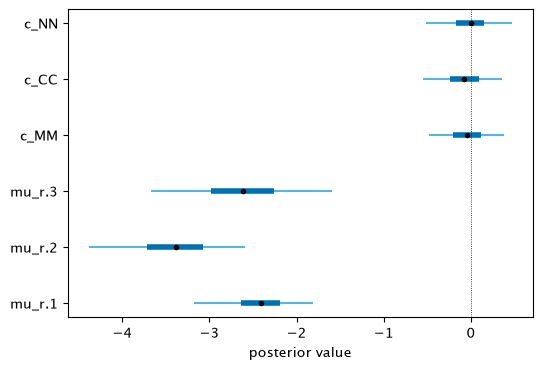

In [4]:
import pandas as pd

from symphony_dt.plots import plot_effects

frame = pd.DataFrame({name: result.draws(name).ravel() for name in
                      ["mu_r.1", "mu_r.2", "mu_r.3", "c_MM", "c_CC", "c_NN"]})
plot_effects(frame);

## Exact-route forecasts

In [5]:
from symphony_dt.forecast import forecast_exact

forecast = forecast_exact(result, split, total_keep=400, output_dir="tutorial_forecast")
forecast.quantiles().head()

,i,k,node,t,anchor_t,horizon,y,cohort,sex,q025,q25,q5,q75,q975
0,1,1,8,2.532512,1.46475,1.067762,22.782353,PD,1,7.411149,18.376143,24.751213,29.908010,39.724310
1,1,2,8,2.532512,1.46475,1.067762,29.704569,PD,1,17.925058,23.666464,27.366257,30.000000,30.000000
2,1,3,8,2.532512,1.46475,1.067762,37.000836,PD,1,1.151313,8.166744,14.478481,23.528881,40.291415
3,1,1,12,4.522930,1.46475,3.058179,42.852491,PD,1,10.940205,22.420889,28.035972,33.407337,45.911369
4,1,2,12,4.522930,1.46475,3.058179,30.000000,PD,1,16.351740,23.734272,26.920603,30.000000,30.000000


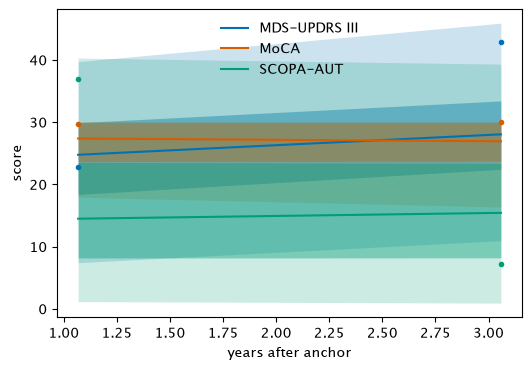

In [6]:
forecast.plot(participant=int(split.meta["i"].iloc[0]));

## Score against LOCF and the linear mixed model

The specification is frozen before scoring. Scoring refuses an unfrozen specification.

In [7]:
from symphony_dt.evaluate import ScoringSpec, freeze_spec, score_fold

spec = ScoringSpec.default()
frozen = freeze_spec(spec)
scores = score_fold(split.fit.data, split.targets.data, split.meta, forecast.draws, tests,
                    spec=spec, frozen=frozen)
print("\n".join(scores.lines[:4]))

UPDRS-III next n=   16/   16  cov95 twin 1.000 locf 0.938 lmm 0.875 | cov50 twin 0.312 locf 0.438 lmm 0.438 | CRPS twin 5.316 locf 5.890 lmm 5.102 | dCRPS-locf -0.574 [-2.312,+0.954] dCRPS-lmm +0.214 [-0.361,+0.806]
UPDRS-III 1y   n=   10/   10  cov95 twin 1.000 locf 0.900 lmm 0.800 | cov50 twin 0.400 locf 0.500 lmm 0.600 | CRPS twin 5.186 locf 5.865 lmm 5.173 | dCRPS-locf -0.679 [-3.420,+1.711] dCRPS-lmm +0.013 [-0.605,+0.577]
UPDRS-III 2y   n=    4/    4  cov95 twin 1.000 locf 1.000 lmm 1.000 | cov50 twin 0.000 locf 0.250 lmm 0.000 | CRPS twin 5.514 locf 6.403 lmm 5.630 | dCRPS-locf -0.889 [-3.472,+0.445] dCRPS-lmm -0.116 [-0.851,+0.541]
UPDRS-III all  n=   45/   45  cov95 twin 1.000 locf 0.956 lmm 0.933 | cov50 twin 0.489 locf 0.489 lmm 0.556 | CRPS twin 4.665 locf 5.042 lmm 4.688 | dCRPS-locf -0.377 [-1.381,+0.230] dCRPS-lmm -0.023 [-0.415,+0.323]


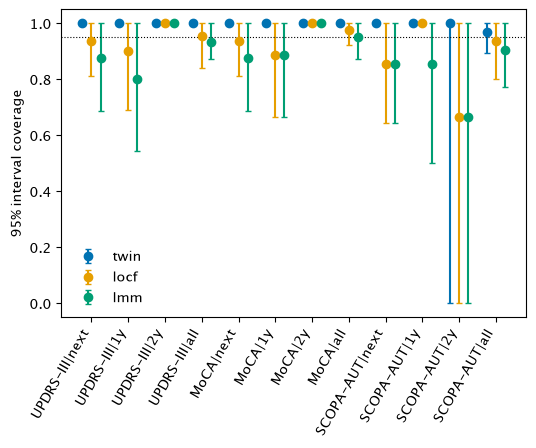

In [8]:
from symphony_dt.plots import plot_coverage_by_window, plot_crps_differences

plot_coverage_by_window(scores.scores);

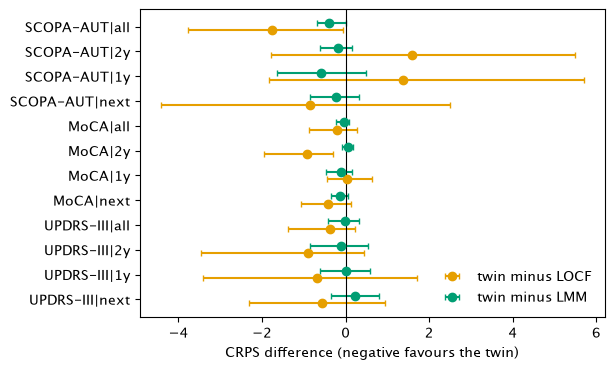

In [9]:
plot_crps_differences(scores.scores);

## The fast route (EXPERIMENTAL)

Forecast one participant from the population draws without refitting.

In [10]:
from symphony_dt.data import Standardisation
from symphony_dt.forecast import forecast_fast

pid = ids[tests[0]]
history = cohort.dataset.subset([pid])
fast = forecast_fast(result, history, [1.0, 2.0], standardisation=Standardisation.fit(cohort.dataset),
                     n_particles=1000, n_draws=200, seed=1)
fast.quantiles()

,k,endpoint,horizon,participant_id,q025,q25,q5,q75,q975
0,1,updrs3,1.0,00002,18.335636,28.972707,34.722294,40.677872,51.884768
1,2,moca,1.0,00002,18.011642,25.442578,28.070158,30.000000,30.000000
2,3,scopa_aut,1.0,00002,2.131009,11.487102,18.169556,25.838106,41.534676
3,1,updrs3,2.0,00002,19.417293,30.279645,36.516014,43.305661,52.966321
4,2,moca,2.0,00002,19.967398,25.612115,28.714754,30.000000,30.000000
5,3,scopa_aut,2.0,00002,1.445860,8.659074,17.336027,26.632810,42.364655
